# Getting to know your data

**Worksheet · Data 110 · Fall 2026 · Week 10**
Rebin Muhammad

This is the worksheet for the lecture. Do it in class, after the slides. Run each cell with **Shift+Enter**, from the top.

Under each exercise there is an empty cell. Write your solution in that cell, then run it. This file does not contain the answers.

## How to open this in Google Colab

1. Go to [colab.research.google.com](https://colab.research.google.com).
2. Choose **File → Upload notebook** and select this file.
3. Upload `NCbirths.csv` before you run the data cells. Click the **folder icon** on the left, then the **upload icon**. The name must stay the same. Colab forgets uploaded files when the session ends, so you upload it again next time.


## Setup

pandas holds the tables. matplotlib draws the charts.


In [75]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import scipy.stats as stats  # for KDE

# The spines are the four lines that make the frame.
# False hides the top line and the right line.
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## The file

`NCbirths.csv` has one row per birth. There are 1,450 rows and 15 columns. The rows are a sample of births in North Carolina in 2001.

`read_csv` turns the file into a table. It already reads the text `#N/A` as a blank, so `Gained` arrives with missing values. The number `-999` in `Weeks` is kept, because it is a number.


In [76]:
births = pd.read_csv("https://raw.github.com/Alissa-Ouspen/data110_alissa/main/datasets/NCbirths.csv", index_col = 0)
# Display the head without the style index if desired, or just standard display:
#display(births.head())

# another way to drop the extra index column:
# births = births.drop(columns = ["Unnamed : 0"])


----------
#### To avoid exporting an index when saving:

`births.to_csv("births_cleaned.csv", index = False)`

------------

## 1. How big is the table?

**Exercise.** Print the number of rows and the number of columns.

`shape` is a pair: rows, then columns.


In [77]:
births.shape



(1450, 14)

#### ***The births table is 1450 rows and 15 columns.***

## 2. Where are the blanks?

**Exercise.** Count the missing values in every column.

`isna` is `True` on a blank cell. `sum` counts those `True` values in each column. A blank is not the same thing as a number such as `-999`.


In [78]:
births.isna().sum()


,0
Plural,0
Sex,0
MomAge,0
Weeks,0
Marital,0
RaceMom,0
HispMom,0
Gained,40
Smoke,5
BirthWeightOz,0


#### ***There are fourty cells with missing data in the "Gained" column and five cells in the "Smoke" column.  The rest seem contain some value.***

## 3. The week that cannot be a gestation

**Exercise.** Show the rows where `Weeks` is below 0, and print how many such rows there are.

A completed pregnancy is not a negative number of weeks. In this file that negative number is `-999`.


In [79]:
#births.info()

# check whether there are such small numbers
#births.describe()

In [80]:
wrong_gestation = births[(births["Weeks"] <= 0)]

print(wrong_gestation)


      Plural  Sex  MomAge  Weeks  Marital  RaceMom HispMom  Gained  Smoke  \
ID                                                                          
1118       1    1      20   -999        2        2       N     NaN    0.0   

      BirthWeightOz  BirthWeightGm  Low  Premie MomRace  
ID                                                       
1118            136         3855.6    0       1   black  


#### ***There is one row where the gestation period is entered as less than 0.***

## 4. Turn the sentinel into a blank

**Exercise.** On a copy of the table, replace every negative `Weeks` with a missing value. Then print the minimum and the mean of `Weeks`.

`copy` keeps the original `births` table unchanged. `loc` selects the rows. `pd.NA` is a blank. `mean` skips blanks, so the mean changes once `-999` is no longer a number.


In [81]:
births_cleaned = births.copy()
# births_cleaned.head()

In [82]:
births_cleaned.loc[births_cleaned["Weeks"] <= 0, "Weeks"] = np.nan

births_cleaned.describe()

,Plural,Sex,MomAge,Weeks,Marital,RaceMom,Gained,Smoke,BirthWeightOz,BirthWeightGm,Low,Premie
count,1450.000000,1450.000000,1450.000000,1449.000000,1450.000000,1450.000000,1410.000000,1445.000000,1450.000000,1450.000000,1450.000000,1450.000000
mean,1.036552,1.486897,26.758621,38.621118,1.344828,1.831034,30.601418,0.144637,116.247586,3295.619069,0.086207,0.131724
std,0.201894,0.500001,6.097297,2.699114,0.475476,1.491546,13.877493,0.351856,22.327231,632.977007,0.280766,0.338307
min,1.000000,1.000000,13.000000,22.000000,1.000000,1.000000,0.000000,0.000000,12.000000,340.200000,0.000000,0.000000
25%,1.000000,1.000000,22.000000,38.000000,1.000000,1.000000,20.000000,0.000000,106.000000,3005.100000,0.000000,0.000000
50%,1.000000,1.000000,26.000000,39.000000,1.000000,1.000000,30.000000,0.000000,118.000000,3345.300000,0.000000,0.000000
75%,1.000000,2.000000,31.000000,40.000000,2.000000,2.000000,40.000000,0.000000,130.000000,3685.500000,0.000000,0.000000
max,3.000000,2.000000,43.000000,45.000000,2.000000,8.000000,95.000000,1.000000,181.000000,5131.350000,1.000000,1.000000


#### ***Now the minimum number of weeks is 22, which is reasonable.***

## 5. Turn the sex code into a word

**Exercise.** Add a column `sex_word`. Code `1` becomes `male` and code `2` becomes `female`. Then count the two words.

`map` looks up each number in a dictionary. Use `{1: "male", 2: "female"}`.


In [83]:
# Working Solution A:
      # mapping

# map Sex codes 1 and 2 to 'male' and 'female'
births_cleaned["sex_word"] = births_cleaned["Sex"].map({1: "male", 2: "female"})

word_counts = births_cleaned["sex_word"].value_counts()
print(word_counts)

sex_word
male      744
female    706
Name: count, dtype: int64


In [84]:
# verify it worked

# births_cleaned.head()

In [85]:
# Working Solution B:
    # np.where() as a vectorized if-else statement

#births_cleaned["SexWord"] = np.where(births_cleaned["Sex"] == 1, "male", "female")

In [86]:
# Working Solution C:
    # explicit if-else statement inside a list comprehension
# births_cleaned["SexWord"] = ["male" if sex == 1 else "female" for sex in births_cleaned["Sex"]]

# if births_cleaned["Sex"] == 1:
#    births_cleaned["SexWord"] = "male"
# else:
#    births_cleaned["SexWord"] = "female"

## 6. The shape of the real weeks

**Exercise.** Draw a histogram of `Weeks` after the negative value has been replaced with a blank. Use bins that are one week wide. Label the horizontal axis `completed weeks` and the vertical axis `births`.

Drop the blank before you draw, with `dropna`. One bar per week is `bins` set to a sequence of edges one week apart. The real weeks run from 22 to 45.


In [87]:


weeks_clean = births_cleaned["Weeks"].dropna()

# bins from 22 to 46, each bin 1 week wide
bin_edges = range(22, 47)

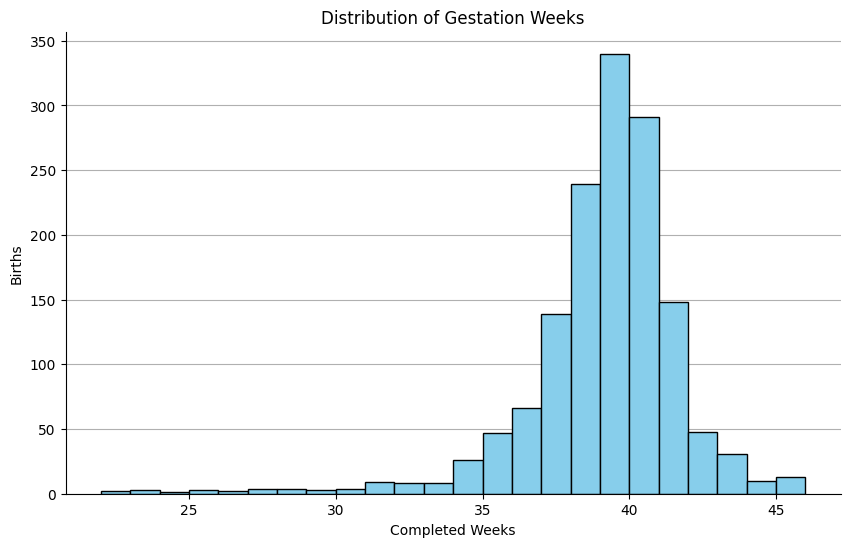

In [88]:
plt.figure(figsize = (10, 6))
plt.hist(weeks_clean, bins = bin_edges, edgecolor = "black", color = "skyblue")

plt.xlabel("Completed Weeks")
plt.ylabel("Births")
plt.title("Distribution of Gestation Weeks")
plt.grid(axis = "y")
plt.gca().set_axisbelow(True)

plt.show()

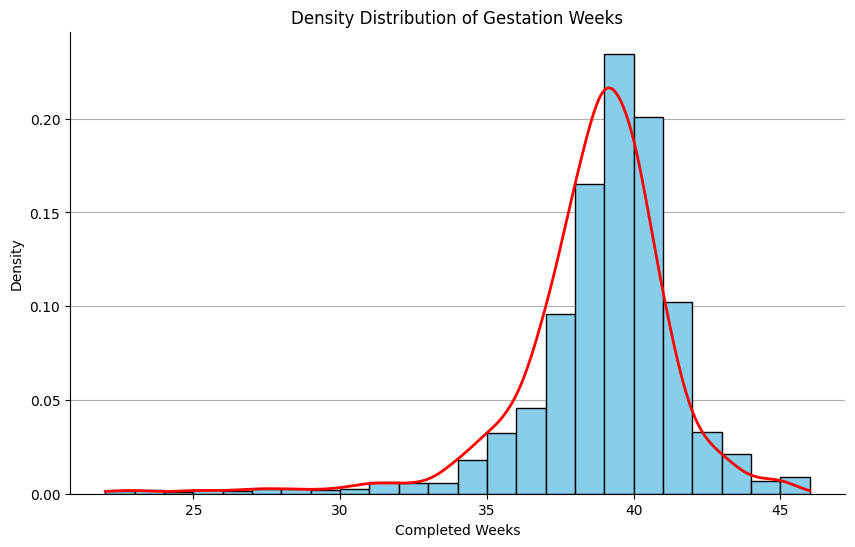

In [89]:
plt.figure(figsize = (10, 6))
plt.hist(weeks_clean, bins = bin_edges, edgecolor = "black", color = "skyblue", density = True)

# Calculate a smooth Kernel Density Estimate (KDE) distribution line
kde = stats.gaussian_kde(weeks_clean)
x_axis = np.linspace(22, 46, 1000)
plt.plot(x_axis, kde(x_axis), color = "red", linewidth = 2, label = "Density")

plt.xlabel("Completed Weeks")
plt.ylabel("Density")
plt.title("Density Distribution of Gestation Weeks")
plt.grid(axis = "y")
plt.gca().set_axisbelow(True)

plt.show()

-------------

### Distribution of absolute birth counts and KDE line combined
####  showing two y-axes

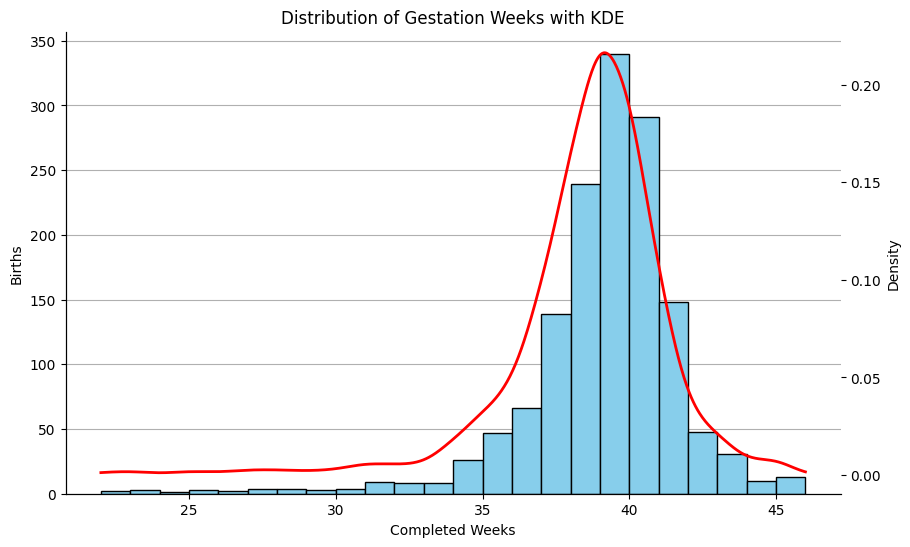

In [90]:
fig, ax1 = plt.subplots(figsize = (10, 6))

# primary y-axis is births count
ax1.hist(weeks_clean, bins = bin_edges, edgecolor = "black", color = "skyblue")
ax1.set_xlabel("Completed Weeks")
ax1.set_ylabel("Births")
ax1.set_title("Distribution of Gestation Weeks with KDE")
ax1.grid(axis = "y")
ax1.set_axisbelow(True)

# secondary y-axis for distribution density line
ax2 = ax1.twinx()

# calculate Kernel Density Estimate (KDE)
kde = stats.gaussian_kde(weeks_clean)
x_axis = np.linspace(22, 46, 1000)
ax2.plot(x_axis, kde(x_axis), color = "red", linewidth = 2, label = "Density")
ax2.set_ylabel("Density")

plt.show()